# Homework 5.2 - Step 10

## Discretization Sensitivity: Coarse, Baseline, and Fine Boxes

This notebook tests how phase-space resolution changes both geometry and next-token prediction.

The comparison uses three uniform discretizations:

$$
8\times8\times8,
\qquad
12\times12\times12,
\qquad
20\times20\times20.
$$

The physical lower and upper bounds are held fixed at the training-fitted bounds from Steps 2-4.

The Markov context length is also held fixed at the value selected on the baseline validation experiment in Steps 5-6.

Therefore this notebook changes **only the discretization resolution**.

## Quantities compared

For each resolution, we record:

1. possible vocabulary size

$$
|\mathcal V_{\text{possible}}|=N^3;
$$

2. number of training boxes actually visited;
3. next-token validation and test accuracy;
4. fraction of exact test histories unseen during training;
5. geometric quantization error.

For a true continuous state $$X_i$$ and the center $$c(a_i)$$ of its token box, define

$$
e_i
=
\|X_i-c(a_i)\|_2.
$$

The quantization RMSE is

$$
\sqrt{
\frac{1}{N}
\sum_i
e_i^2
}.
$$

A coarse partition may reduce vocabulary size and simplify the sequence problem, but it can also increase geometric approximation error. A fine partition may reduce quantization error while creating many more possible tokens and histories. These are hypotheses to test, not conclusions assumed in advance.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw5_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw5_2"
TRAJECTORY_DIR = DATA_DIR / "trajectories"

configuration = json.loads(
    (
        DATA_DIR
        / "baseline_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

selection = json.loads(
    (
        DATA_DIR
        / "task5_6_selected_markov_model.json"
    ).read_text(
        encoding="utf-8"
    )
)

SELECTED_M = int(
    selection[
        "selected_context_length_m"
    ]
)

LOWER = np.asarray(
    configuration[
        "training_fitted_lower_bounds"
    ],
    dtype=float,
)

UPPER = np.asarray(
    configuration[
        "training_fitted_upper_bounds"
    ],
    dtype=float,
)

RESOLUTIONS = [8, 12, 20]

print("Fixed selected m:", SELECTED_M)
print("Fixed lower bounds:", LOWER)
print("Fixed upper bounds:", UPPER)

Fixed selected m: 3
Fixed lower bounds: [-20.55109215 -27.92413737   0.65950703]
Fixed upper bounds: [20.7604415  28.61696747 48.79435059]


In [2]:
def load_continuous_books(split_name):
    paths = sorted(
        (TRAJECTORY_DIR / split_name)
        .glob("book_*.npz")
    )

    books = []

    for path in paths:
        data = np.load(path)
        books.append(data["states"])

    return books


train_state_books = load_continuous_books(
    "train"
)

validation_state_books = (
    load_continuous_books(
        "validation"
    )
)

test_state_books = load_continuous_books(
    "test"
)

print("Training books:", len(train_state_books))
print("Validation books:", len(validation_state_books))
print("Test books:", len(test_state_books))

Training books: 40
Validation books: 10
Test books: 10


In [3]:
def make_edges(n):
    return [
        np.linspace(
            LOWER[axis],
            UPPER[axis],
            n + 1,
        )
        for axis in range(3)
    ]


def tokenize_states(states, n, edges):
    indices = []
    clipped = np.zeros(
        len(states),
        dtype=bool,
    )

    for axis in range(3):
        values = states[:, axis]

        raw = np.searchsorted(
            edges[axis],
            values,
            side="right",
        ) - 1

        clipped |= (
            (values < edges[axis][0])
            | (values > edges[axis][-1])
        )

        idx = np.clip(
            raw,
            0,
            n - 1,
        ).astype(int)

        indices.append(idx)

    ix, iy, iz = indices

    tokens = (
        ix * n * n
        + iy * n
        + iz
    )

    return (
        tokens.astype(np.int64),
        clipped,
    )


def token_centers(tokens, n, edges):
    tokens = np.asarray(
        tokens,
        dtype=np.int64,
    )

    ix = tokens // (n * n)
    rem = tokens % (n * n)
    iy = rem // n
    iz = rem % n

    x = 0.5 * (
        edges[0][ix]
        + edges[0][ix + 1]
    )

    y = 0.5 * (
        edges[1][iy]
        + edges[1][iy + 1]
    )

    z = 0.5 * (
        edges[2][iz]
        + edges[2][iz + 1]
    )

    return np.column_stack(
        [x, y, z]
    )

In [4]:
def fit_model(books, max_order):
    models = {
        order: defaultdict(Counter)
        for order in range(
            1,
            max_order + 1,
        )
    }

    unigram = Counter()

    for sequence in books:
        unigram.update(
            sequence.tolist()
        )

        for order in range(
            1,
            max_order + 1,
        ):
            for i in range(
                order,
                len(sequence),
            ):
                history = tuple(
                    int(x)
                    for x in sequence[
                        i-order:i
                    ]
                )

                next_token = int(
                    sequence[i]
                )

                models[order][history][
                    next_token
                ] += 1

    global_mode = min(
        unigram,
        key=lambda token: (
            -unigram[token],
            token,
        ),
    )

    return models, unigram, global_mode


def deterministic_mode(counter):
    return min(
        counter,
        key=lambda token: (
            -counter[token],
            token,
        ),
    )


def evaluate_model(
    books,
    models,
    global_mode,
    m,
):
    total = 0
    correct = 0
    exact_seen = 0

    for sequence in books:
        for i in range(
            m,
            len(sequence),
        ):
            history = tuple(
                int(x)
                for x in sequence[
                    i-m:i
                ]
            )

            truth = int(
                sequence[i]
            )

            if history in models[m]:
                exact_seen += 1

            prediction = None

            for order in range(
                m,
                0,
                -1,
            ):
                key = history[
                    -order:
                ]

                if key in models[order]:
                    prediction = (
                        deterministic_mode(
                            models[order][key]
                        )
                    )
                    break

            if prediction is None:
                prediction = global_mode

            correct += int(
                prediction == truth
            )

            total += 1

    return {
        "accuracy": (
            correct / total
        ),
        "exact_history_coverage": (
            exact_seen / total
        ),
        "unseen_exact_history_fraction": (
            1.0
            - exact_seen / total
        ),
    }

## Run the three-resolution experiment

In [5]:
records = []

for n in RESOLUTIONS:
    edges = make_edges(n)

    split_token_books = {}
    clipping_by_split = {}

    for split_name, state_books in [
        ("train", train_state_books),
        ("validation", validation_state_books),
        ("test", test_state_books),
    ]:
        token_books = []
        clip_count = 0
        point_count = 0

        for states in state_books:
            tokens, clipped = (
                tokenize_states(
                    states,
                    n,
                    edges,
                )
            )

            token_books.append(
                tokens
            )

            clip_count += int(
                clipped.sum()
            )

            point_count += len(
                clipped
            )

        split_token_books[
            split_name
        ] = token_books

        clipping_by_split[
            split_name
        ] = (
            clip_count
            / point_count
        )

    train_tokens = split_token_books[
        "train"
    ]

    validation_tokens = (
        split_token_books[
            "validation"
        ]
    )

    test_tokens = split_token_books[
        "test"
    ]

    models, unigram, global_mode = (
        fit_model(
            train_tokens,
            SELECTED_M,
        )
    )

    validation_result = (
        evaluate_model(
            validation_tokens,
            models,
            global_mode,
            SELECTED_M,
        )
    )

    test_result = evaluate_model(
        test_tokens,
        models,
        global_mode,
        SELECTED_M,
    )

    all_train_tokens = np.concatenate(
        train_tokens
    )

    observed_train_vocabulary = len(
        np.unique(
            all_train_tokens
        )
    )

    squared_errors = []

    for states, tokens in zip(
        test_state_books,
        test_tokens,
    ):
        centers = token_centers(
            tokens,
            n,
            edges,
        )

        error_squared = np.sum(
            (states - centers) ** 2,
            axis=1,
        )

        squared_errors.append(
            error_squared
        )

    quantization_rmse = float(
        np.sqrt(
            np.mean(
                np.concatenate(
                    squared_errors
                )
            )
        )
    )

    records.append({
        "bins_per_axis": n,
        "possible_vocabulary_size": n ** 3,
        "observed_training_vocabulary_size": (
            observed_train_vocabulary
        ),
        "fixed_context_length_m": (
            SELECTED_M
        ),
        "validation_accuracy": (
            validation_result[
                "accuracy"
            ]
        ),
        "validation_exact_history_coverage": (
            validation_result[
                "exact_history_coverage"
            ]
        ),
        "test_accuracy": (
            test_result[
                "accuracy"
            ]
        ),
        "test_exact_history_coverage": (
            test_result[
                "exact_history_coverage"
            ]
        ),
        "test_unseen_exact_history_fraction": (
            test_result[
                "unseen_exact_history_fraction"
            ]
        ),
        "test_quantization_rmse": (
            quantization_rmse
        ),
        "train_clipped_fraction": (
            clipping_by_split[
                "train"
            ]
        ),
        "validation_clipped_fraction": (
            clipping_by_split[
                "validation"
            ]
        ),
        "test_clipped_fraction": (
            clipping_by_split[
                "test"
            ]
        ),
    })


results = pd.DataFrame(
    records
)

results_path = (
    DATA_DIR
    / "task10_discretization_sensitivity.csv"
)

results.to_csv(
    results_path,
    index=False,
)

print(results.to_string(index=False))
print()
print("Saved:", results_path.resolve())

 bins_per_axis  possible_vocabulary_size  observed_training_vocabulary_size  fixed_context_length_m  validation_accuracy  validation_exact_history_coverage  test_accuracy  test_exact_history_coverage  test_unseen_exact_history_fraction  test_quantization_rmse  train_clipped_fraction  validation_clipped_fraction  test_clipped_fraction
             8                       512                                117                       3             0.773077                           0.997436       0.776042                     0.996635                            0.003365                3.063278                     0.0                          0.0                    0.0
            12                      1728                                250                       3             0.757212                           0.995433       0.759135                     0.994471                            0.005529                2.041712                     0.0                          0.0                

## Vocabulary growth

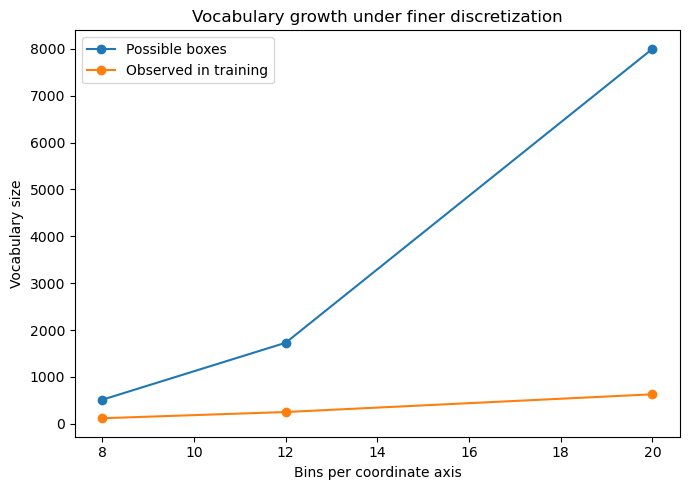

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step10_vocabulary_vs_resolution.png


In [6]:
plt.figure(figsize=(7, 5))

plt.plot(
    results[
        "bins_per_axis"
    ],
    results[
        "possible_vocabulary_size"
    ],
    marker="o",
    label="Possible boxes",
)

plt.plot(
    results[
        "bins_per_axis"
    ],
    results[
        "observed_training_vocabulary_size"
    ],
    marker="o",
    label="Observed in training",
)

plt.xlabel("Bins per coordinate axis")
plt.ylabel("Vocabulary size")
plt.title("Vocabulary growth under finer discretization")
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step10_vocabulary_vs_resolution.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

## Prediction accuracy versus resolution

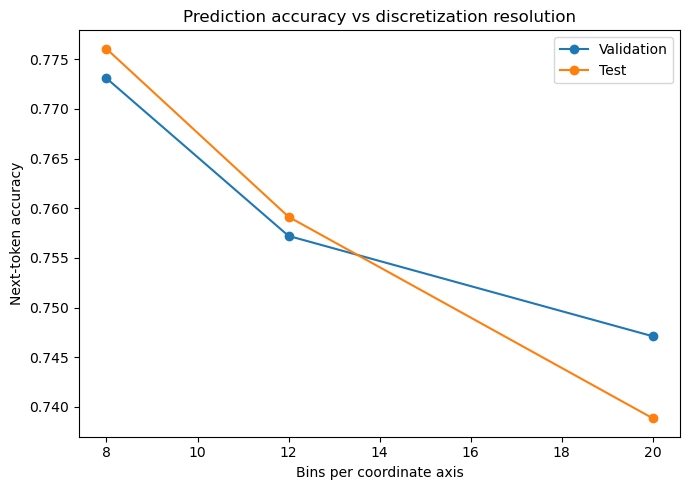

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step10_accuracy_vs_resolution.png


In [7]:
plt.figure(figsize=(7, 5))

plt.plot(
    results[
        "bins_per_axis"
    ],
    results[
        "validation_accuracy"
    ],
    marker="o",
    label="Validation",
)

plt.plot(
    results[
        "bins_per_axis"
    ],
    results[
        "test_accuracy"
    ],
    marker="o",
    label="Test",
)

plt.xlabel("Bins per coordinate axis")
plt.ylabel("Next-token accuracy")
plt.title("Prediction accuracy vs discretization resolution")
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step10_accuracy_vs_resolution.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

## Quantization error versus resolution

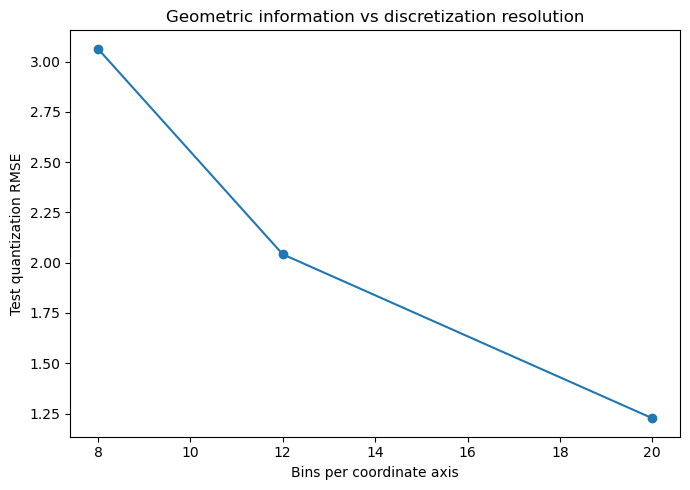

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step10_quantization_error_vs_resolution.png


In [8]:
plt.figure(figsize=(7, 5))

plt.plot(
    results[
        "bins_per_axis"
    ],
    results[
        "test_quantization_rmse"
    ],
    marker="o",
)

plt.xlabel("Bins per coordinate axis")
plt.ylabel("Test quantization RMSE")
plt.title("Geometric information vs discretization resolution")
plt.tight_layout()

path = (
    RESULT_DIR
    / "step10_quantization_error_vs_resolution.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

## Data sparsity versus resolution

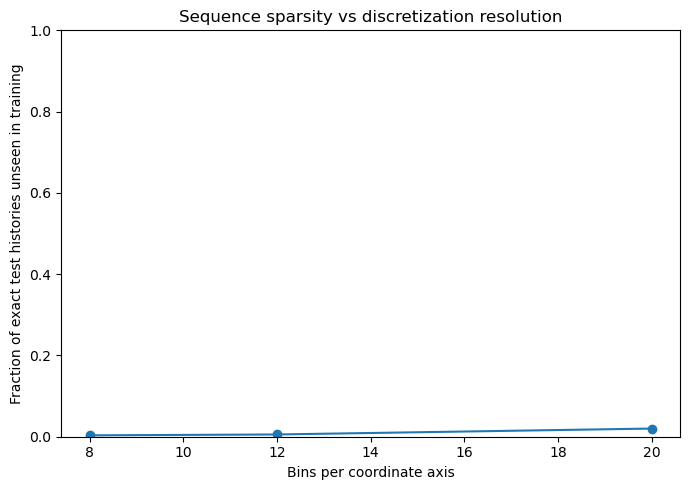

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.2\result images\hw5_2\step10_unseen_history_vs_resolution.png


In [9]:
plt.figure(figsize=(7, 5))

plt.plot(
    results[
        "bins_per_axis"
    ],
    results[
        "test_unseen_exact_history_fraction"
    ],
    marker="o",
)

plt.xlabel("Bins per coordinate axis")
plt.ylabel("Fraction of exact test histories unseen in training")
plt.title("Sequence sparsity vs discretization resolution")
plt.ylim(0.0, 1.0)
plt.tight_layout()

path = (
    RESULT_DIR
    / "step10_unseen_history_vs_resolution.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

## Step 10 interpretation

The result should be interpreted as a tradeoff between two objectives.

A coarser discretization can make the discrete sequence easier to predict because many nearby continuous states share a token. However, that same merging can increase the geometric approximation error.

A finer discretization preserves more geometric information but creates many more possible tokens and histories.

The correct conclusion should follow the measured table rather than assuming in advance that one resolution is best.

## Step 10 outputs

### Data

- `task10_discretization_sensitivity.csv`

### Result images

- `step10_vocabulary_vs_resolution.png`
- `step10_accuracy_vs_resolution.png`
- `step10_quantization_error_vs_resolution.png`
- `step10_unseen_history_vs_resolution.png`